In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

import os

from scipy.stats import gaussian_kde

# Variables

In [150]:
DEALER_POSSIBLE_HIT = ("dealer_hit_16", "dealer_hit_17", "dealer_hit_18")
DECK_NUMBER = ("1", "4", "6", "8")
CARD_PER_SEED = "cards_per_seed.tsv"
VALUE_PER_SEED = "value_per_seed.tsv"

TOTAL_CARDS = "total_cards_appearance.tsv"
TOTAL_VALUES = "total_hand_values_count.tsv"

METRICS = "metrics.tsv"

ROOT_DIR = os.path.join(os.getcwd(), "logs")

PATH2TOTAL_CARDS = [os.path.join(ROOT_DIR, dealer_possible_hit, deck_number, TOTAL_CARDS) for dealer_possible_hit in DEALER_POSSIBLE_HIT for deck_number in DECK_NUMBER]

PATH2ALL_HANDS = [os.path.join(ROOT_DIR, dealer_possible_hit, deck_number, TOTAL_VALUES) for dealer_possible_hit in DEALER_POSSIBLE_HIT for deck_number in DECK_NUMBER]

PATH2ALL_METRICS = [os.path.join(ROOT_DIR, dealer_possible_hit, deck_number, METRICS) for dealer_possible_hit in DEALER_POSSIBLE_HIT for deck_number in DECK_NUMBER]

PATH2FIGURES = os.path.join(ROOT_DIR, "figures")
os.makedirs(PATH2FIGURES, exist_ok=True)

PATH2METRICS_RESULTS = os.path.join(ROOT_DIR, "metrics_results")
os.makedirs(PATH2METRICS_RESULTS, exist_ok=True)

CARD_ORDER = ["10", "2", "3", "4", "5", "6", "7", "8", "9", "A", "J", "K", "Q"]

In [67]:
plt.rcParams["font.size"] = 11
plt.rcParams["font.family"] = "Times New Roman"

# Sanity check: Deck Distribution

In [4]:
all_cards = [pd.read_csv(f, sep="\t") for f in PATH2TOTAL_CARDS]
all_cards[0].head()

,suit,appearances
0,10♥,10288046
1,6♦,10283858
2,3♥,10277517
3,K♦,10292116
4,3♦,10277006


In [5]:
# Percentage column
for df in all_cards:
    df.sort_values("suit", inplace=True)
    df["percentage"] = df["appearances"] *100 / df["appearances"].sum()

print(all_cards[0])

    suit  appearances  percentage
13  10♠      10284938    1.923266
42  10♣      10286223    1.923506
0   10♥      10288046    1.923847
32  10♦      10289986    1.924210
49   2♠      10275256    1.921455
31   2♣      10274554    1.921324
41   2♥      10278355    1.922035
23   2♦      10277584    1.921891
45   3♠      10277893    1.921949
38   3♣      10279020    1.922159
2    3♥      10277517    1.921878
4    3♦      10277006    1.921783
9    4♠      10280763    1.922485
20   4♣      10279925    1.922329
33   4♥      10281210    1.922569
46   4♦      10280725    1.922478
18   5♠      10281333    1.922592
51   5♣      10280257    1.922391
28   5♥      10282520    1.922814
22   5♦      10283210    1.922943
5    6♠      10281212    1.922569
39   6♣      10280172    1.922375
19   6♥      10284278    1.923143
1    6♦      10283858    1.923064
35   7♠      10286135    1.923490
47   7♣      10285964    1.923458
7    7♥      10284534    1.923190
48   7♦      10283245    1.922949
24   8♠      1

## Dealer Hit 16

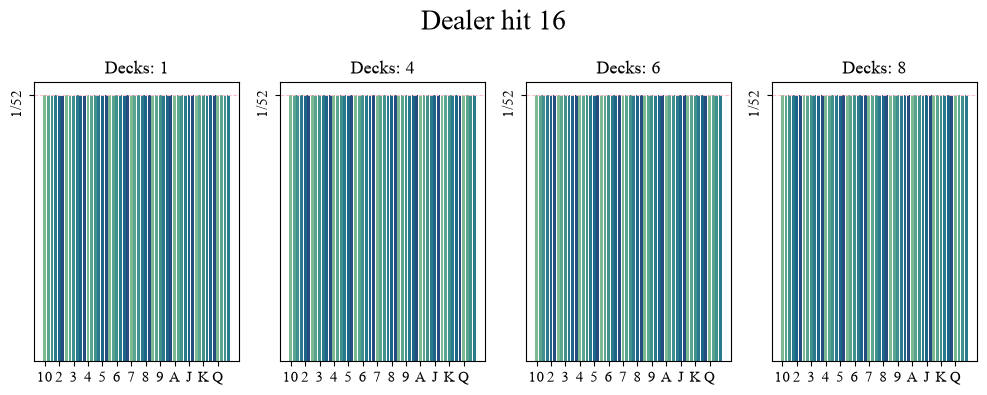

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(10, 4))

for (i,df),deck_number_used in zip(enumerate(all_cards[:4]), DECK_NUMBER):
    ax[i].bar(df["suit"], df.loc[:,"percentage"], color=sns.color_palette("crest"))
    ax[i].set_xticks(range(0, 52, 4))
    ax[i].set_xticklabels(CARD_ORDER)
    ax[i].set_yticks([1/52 *100])
    ax[i].set_yticklabels(["1/52"], rotation=90)
    ax[i].set_title(f"Decks: {deck_number_used}")
    ax[i].axhline(1/52*100, linestyle="--", color="pink", linewidth=.75)

fig.suptitle("Dealer hit 16", 
             fontsize=20)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Dealer_hit_16_sanity_check.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

## Dealer Hit 17

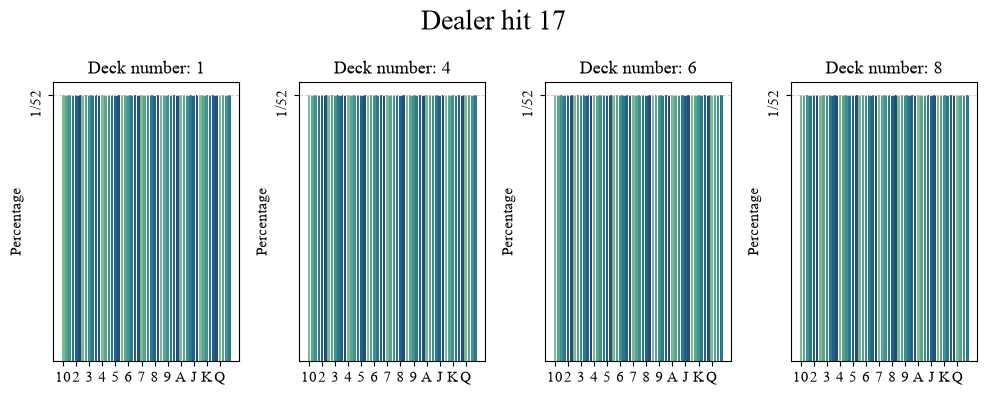

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(10, 4))

for (i,df),deck_number_used in zip(enumerate(all_cards[4:8]), DECK_NUMBER):
    ax[i].bar(df["suit"], df.loc[:,"percentage"], color=sns.color_palette("crest"))
    ax[i].set_xticks(range(0, 52, 4))
    ax[i].set_xticklabels(CARD_ORDER)
    ax[i].set_yticks([1/52 *100])
    ax[i].set_yticklabels(["1/52"], rotation=90)
    ax[i].set_ylabel("Percentage", rotation=90)
    ax[i].set_title(f"Deck number: {deck_number_used}")
    ax[i].axhline(1/52*100, linestyle="--", color="pink", linewidth=.75)

fig.suptitle("Dealer hit 17", 
             fontsize=20)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Dealer_hit_17_sanity_check.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

## Dealer Hit 18

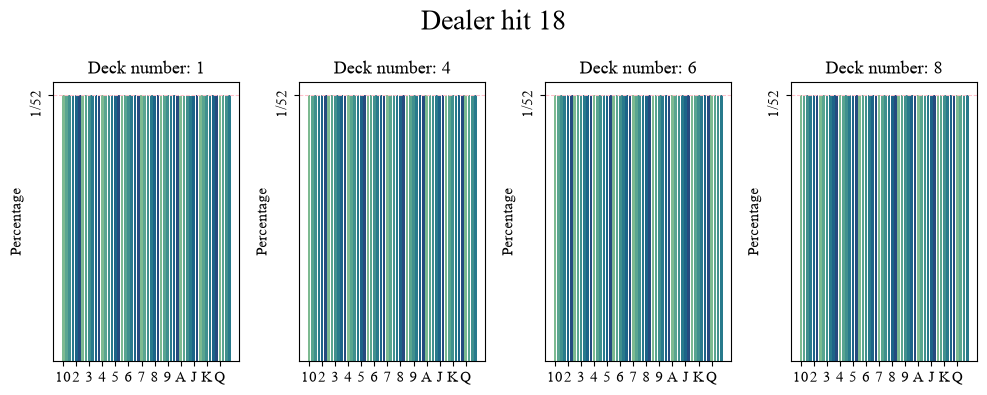

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(10, 4))

for (i,df),deck_number_used in zip(enumerate(all_cards[8:]), DECK_NUMBER):
    ax[i].bar(df["suit"], df.loc[:,"percentage"], color=sns.color_palette("crest"))
    ax[i].set_xticks(range(0, 52, 4))
    ax[i].set_xticklabels(CARD_ORDER)
    ax[i].set_yticks([1/52 *100])
    ax[i].set_yticklabels(["1/52"], rotation=90)
    ax[i].set_ylabel("Percentage", rotation=90)
    ax[i].set_title(f"Deck number: {deck_number_used}")
    ax[i].axhline(1/52*100, linestyle="--", color="pink", linewidth=.75)

fig.suptitle("Dealer hit 18",
             fontsize=20)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Dealer_hit_18_sanity_check.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

# Sanity check: Deck Distribution Per Seed

# Hand values calculation

In [19]:
all_hand_values = [ pd.read_csv(f, sep="\t").set_index("hand_value") for f in PATH2ALL_HANDS]
all_hand_values[0].head(10)

,player_winning_value_count,player_losing_value_count,casino_winning_value_count,casino_losing_value_count
hand_value,,,,
4,0,23953,12030,24011
5,0,63963,34805,64373
6,0,87561,31903,87738
7,0,127090,36580,127329
8,0,150797,37345,151102
9,0,190011,197726,190450
10,0,213720,361227,212899
11,27340,313130,521220,251280
12,892823,2760132,1371694,459552


## Dealer hit 16

In [10]:
hit_16_dfs = all_hand_values[:4]

### Winning hand values

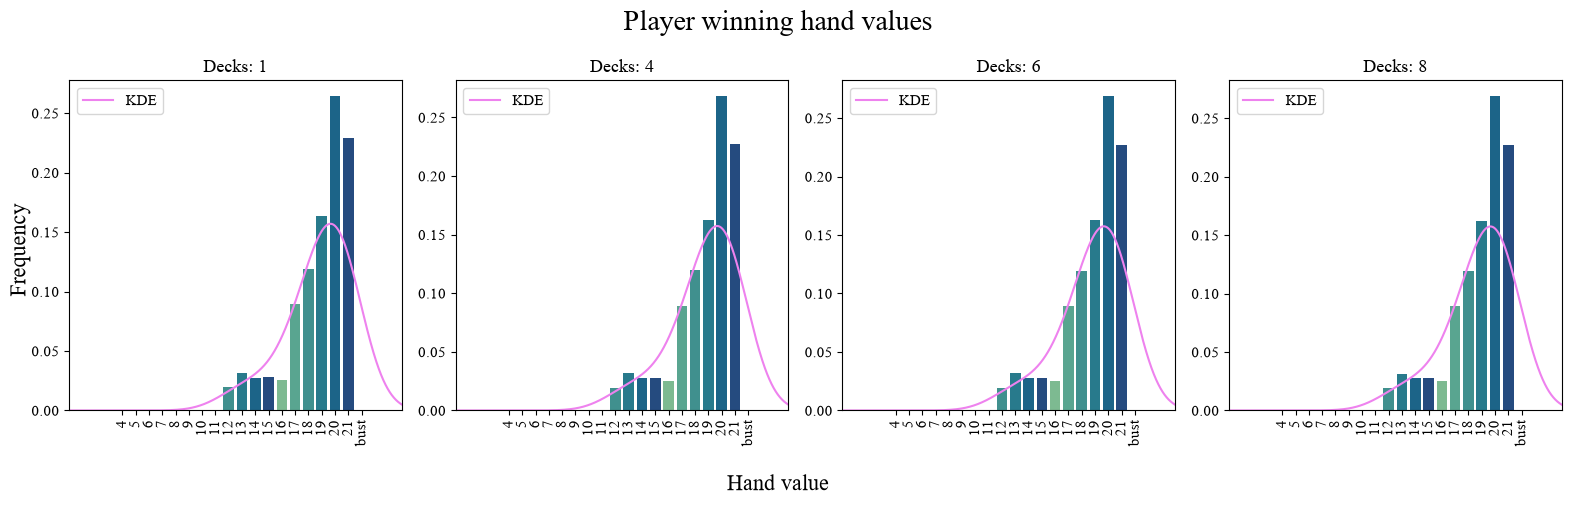

In [55]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_16_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["player_winning_value_count"]/df["player_winning_value_count"].sum(), color=sns.color_palette("crest"))

    values = df.index.to_numpy()
    weights = (df["player_winning_value_count"]/df["player_winning_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="violet", label="KDE")
    ax[i].set_xlim(0, 25)

    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Player winning hand values", fontsize=20)

fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Player_winning_hand_values_16.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

### Losing hand values

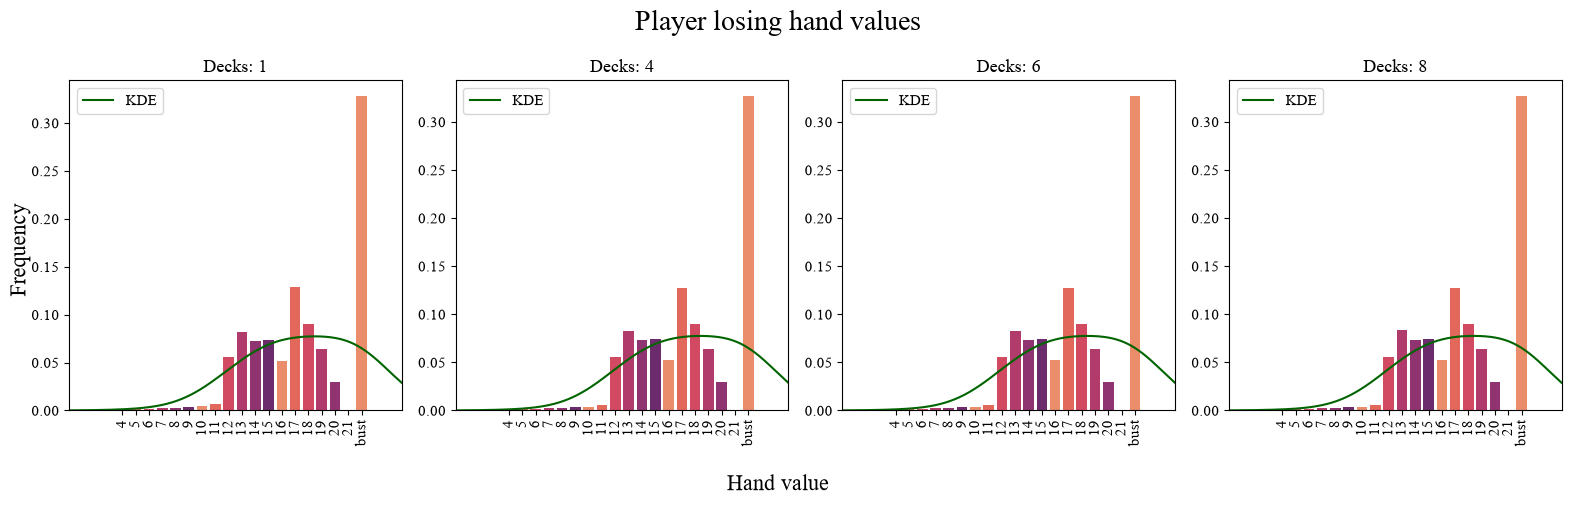

In [46]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_16_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["player_losing_value_count"]/df["player_losing_value_count"].sum(), color=sns.color_palette("flare"))

    values = df.index.to_numpy()
    weights = (df["player_losing_value_count"]/df["player_losing_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="darkgreen", label="KDE")
    ax[i].set_xlim(0, 25)
    
    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Player losing hand values", fontsize=20)
fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Player_losing_hand_values_16.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

### Dealer winning hands

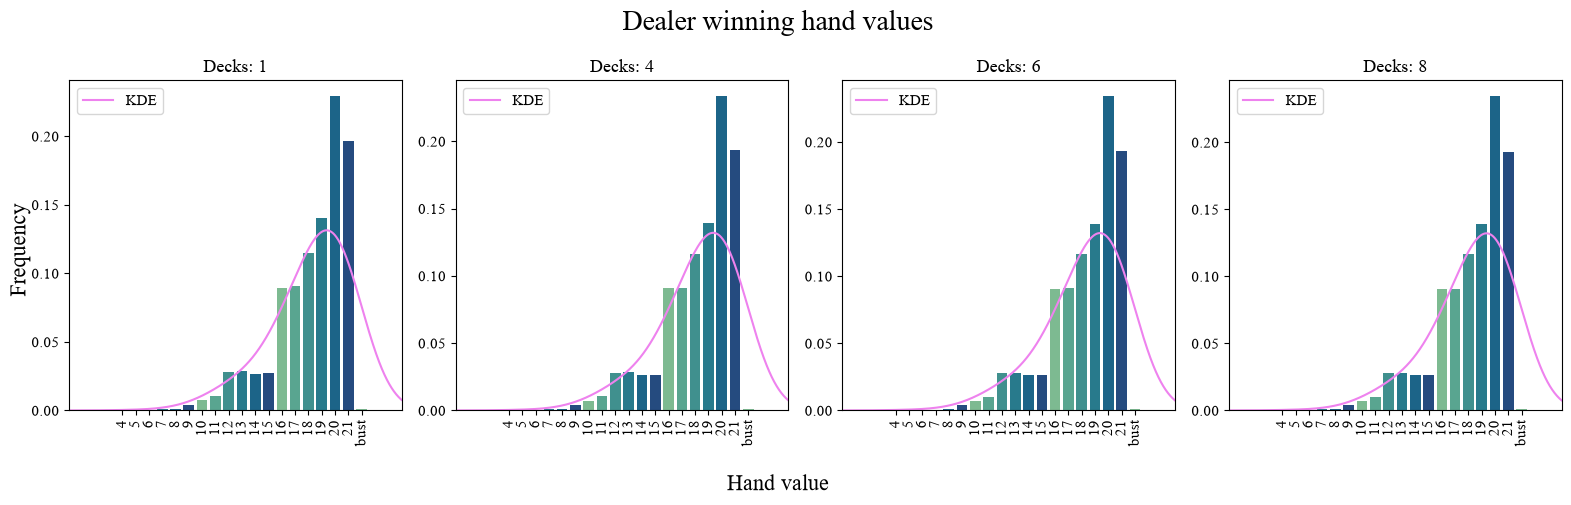

In [57]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_16_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["casino_winning_value_count"]/df["casino_winning_value_count"].sum(), color=sns.color_palette("crest"))

    values = df.index.to_numpy()
    weights = (df["casino_winning_value_count"]/df["casino_winning_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="violet", label="KDE")
    ax[i].set_xlim(0, 25)
    
    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Dealer winning hand values", fontsize=20)
fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Casino_winning_hand_values_16.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

### Dealer losing hands

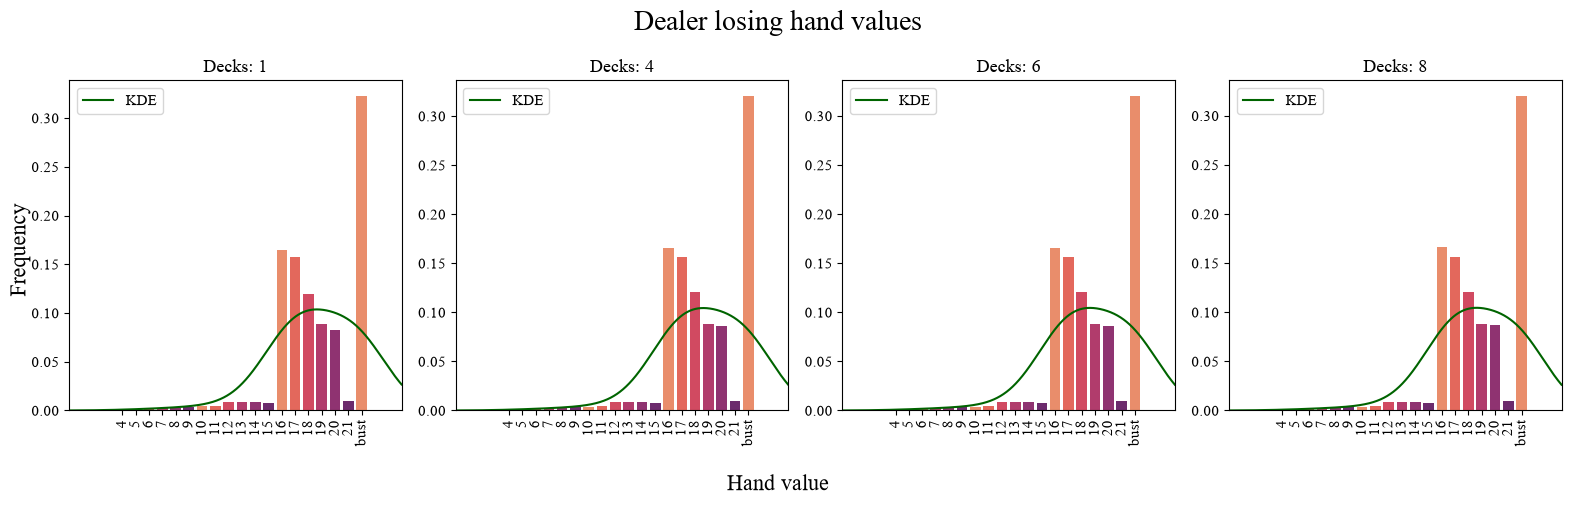

In [58]:
#@TODO: HAS a BUG, NEED TO RE-RUN ALL
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_16_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["casino_losing_value_count"]/df["casino_losing_value_count"].sum(), color=sns.color_palette("flare"))

    values = df.index.to_numpy()
    weights = (df["casino_losing_value_count"]/df["casino_losing_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="darkgreen", label="KDE")
    ax[i].set_xlim(0, 25)
    
    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Dealer losing hand values", fontsize=20)
fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Casino_losing_hand_values_16.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

## Dealer hit 17

In [70]:
plt.rcParams["font.size"] = 11
plt.rcParams["font.family"] = "Times New Roman"

In [71]:
hit_17_dfs = all_hand_values[4:8]
hit_17_dfs[0].head(10)

,player_winning_value_count,player_losing_value_count,casino_winning_value_count,casino_losing_value_count
hand_value,,,,
4,0,24024,12053,24121
5,0,64119,35020,64253
6,0,87697,31925,87847
7,0,127320,36635,127678
8,0,150669,37341,151051
9,0,189338,198179,190175
10,0,213616,361633,212761
11,37723,303140,521478,250818
12,1281597,2373275,1371348,458436


### Winning hand values

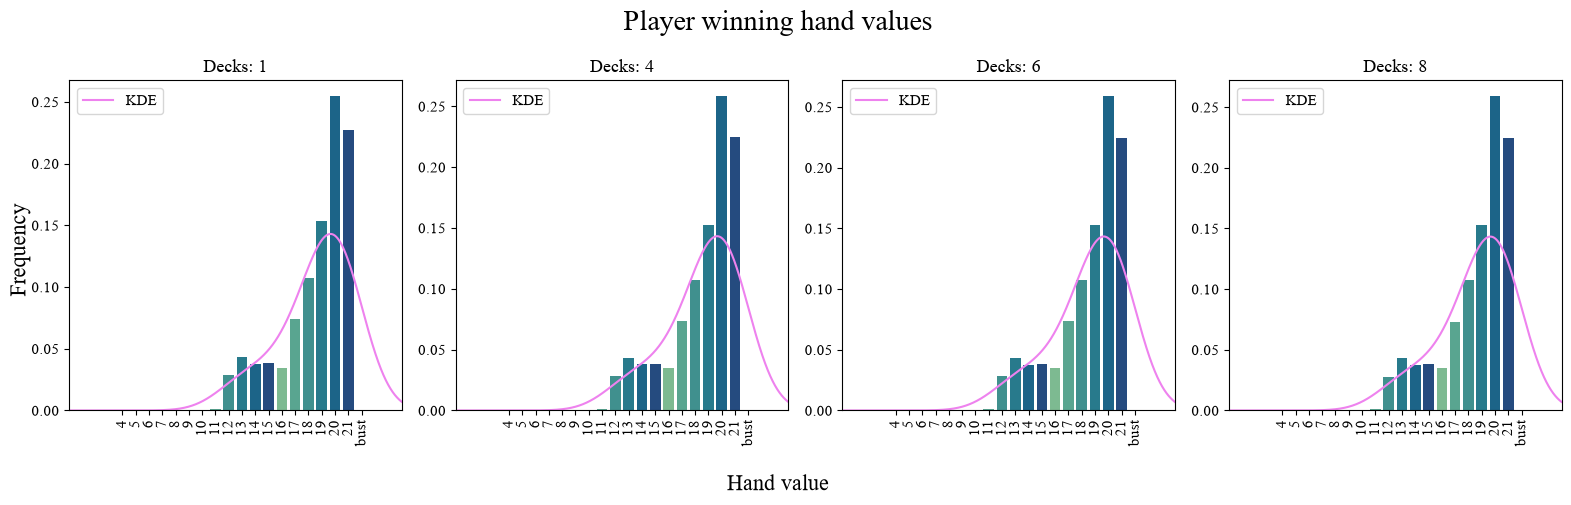

In [68]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_17_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["player_winning_value_count"]/df["player_winning_value_count"].sum(), color=sns.color_palette("crest"))

    values = df.index.to_numpy()
    weights = (df["player_winning_value_count"]/df["player_winning_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="violet", label="KDE")
    ax[i].set_xlim(0, 25)

    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Player winning hand values", fontsize=20)

fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Player_winning_hand_values_17.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

### Losing hand value

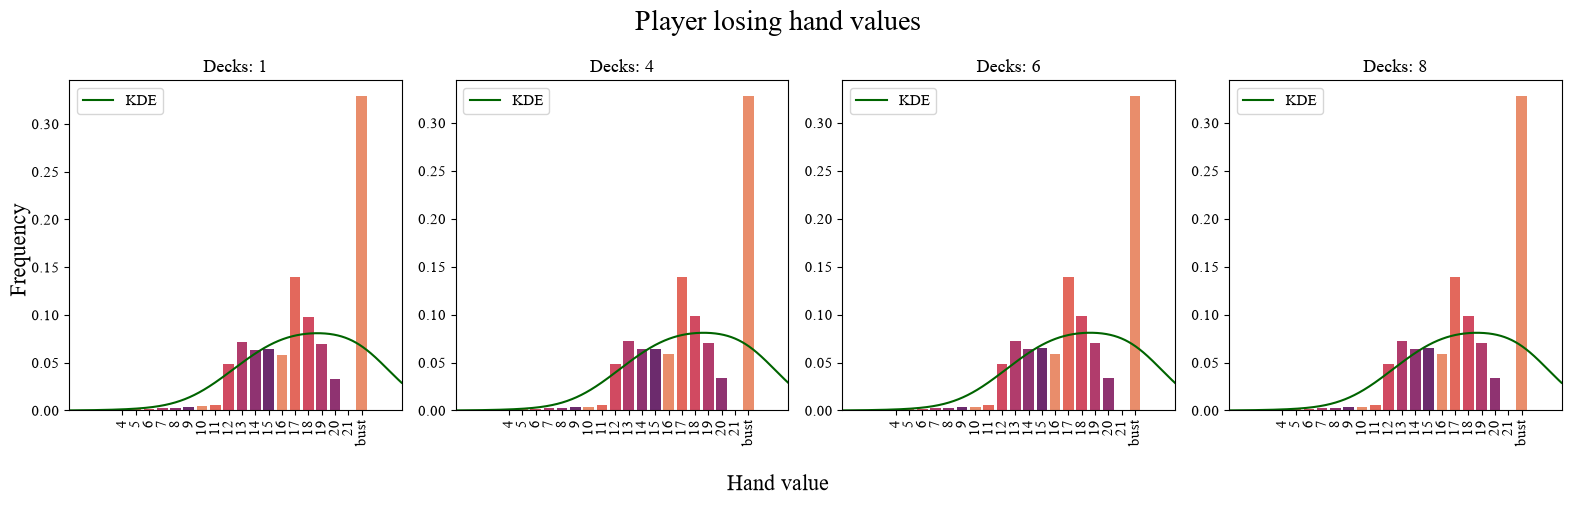

In [72]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_17_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["player_losing_value_count"]/df["player_losing_value_count"].sum(), color=sns.color_palette("flare"))

    values = df.index.to_numpy()
    weights = (df["player_losing_value_count"]/df["player_losing_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="darkgreen", label="KDE")
    ax[i].set_xlim(0, 25)

    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Player losing hand values", fontsize=20)
fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Player_losing_hand_values_17.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

### Dealer winning hands

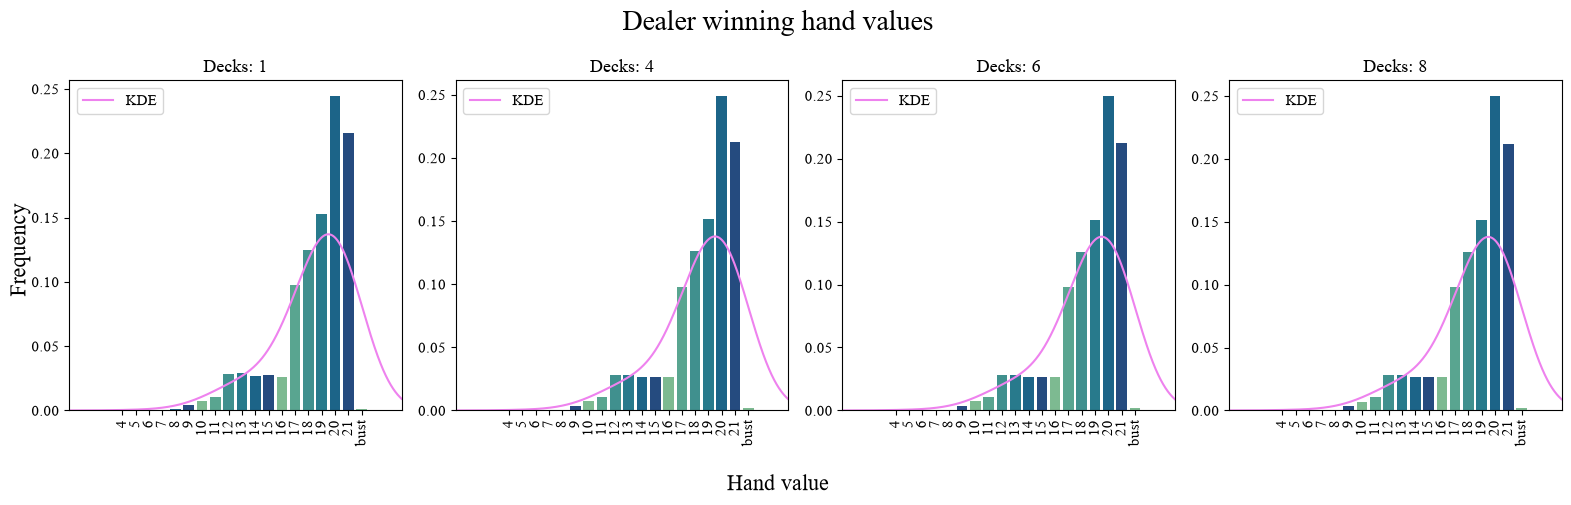

In [82]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_17_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["casino_winning_value_count"]/df["casino_winning_value_count"].sum(), color=sns.color_palette("crest"))

    values = df.index.to_numpy()
    weights = (df["casino_winning_value_count"]/df["casino_winning_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="violet", label="KDE")
    ax[i].set_xlim(0, 25)

    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Dealer winning hand values", fontsize=20)

fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Casino_winning_hand_values_17.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

### Dealer losing hands

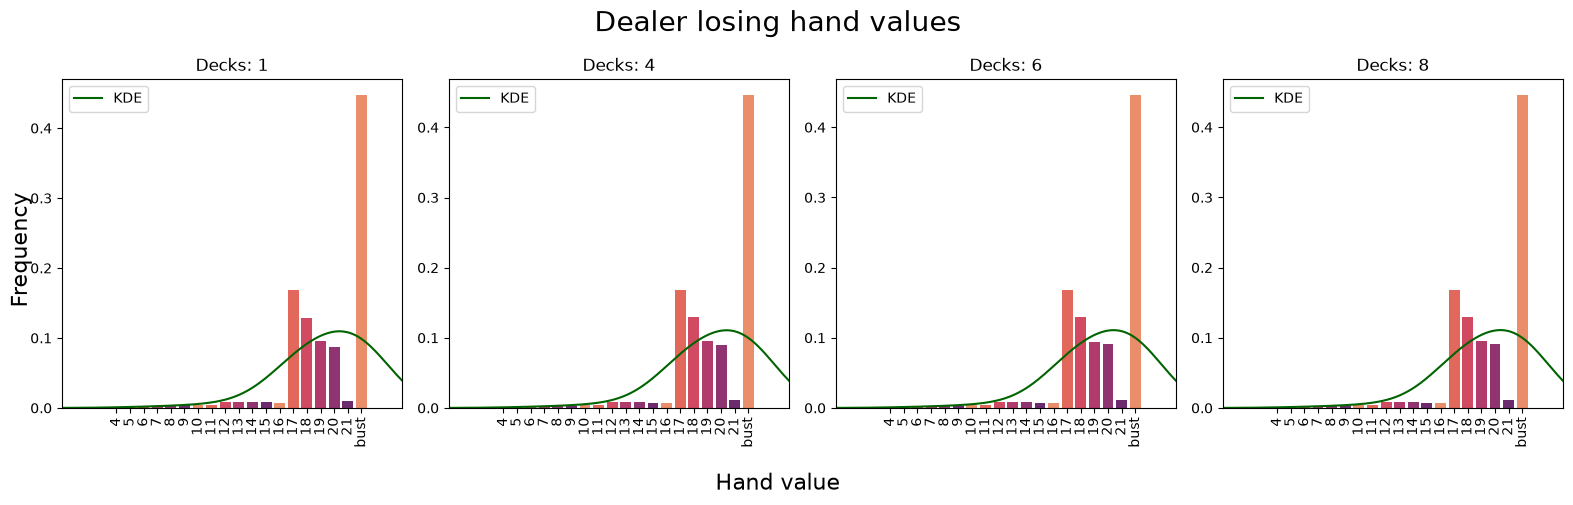

In [74]:
#@TODO: HAS a BUG, NEED TO RE-RUN ALL
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_17_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["casino_losing_value_count"]/df["casino_losing_value_count"].sum(), color=sns.color_palette("flare"))

    values = df.index.to_numpy()
    weights = (df["casino_losing_value_count"]/df["casino_losing_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="darkgreen", label="KDE")
    ax[i].set_xlim(0, 25)

    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Dealer losing hand values", fontsize=20)
fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Casino_losing_hand_values_17.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

## Dealer hit 18

In [76]:
plt.rcParams["font.size"] = 11
plt.rcParams["font.family"] = "Times New Roman"

In [75]:
hit_18_dfs = all_hand_values[8:]
hit_18_dfs[0].head(10)

,player_winning_value_count,player_losing_value_count,casino_winning_value_count,casino_losing_value_count
hand_value,,,,
4,0,24007,12107,23979
5,0,63914,34774,63915
6,0,87546,31876,87646
7,0,127115,36642,126885
8,0,150313,37488,150937
9,0,189377,198094,190349
10,0,213770,361385,212685
11,45623,295215,521770,250885
12,1578424,2076215,1370301,458568


### Player winning hands

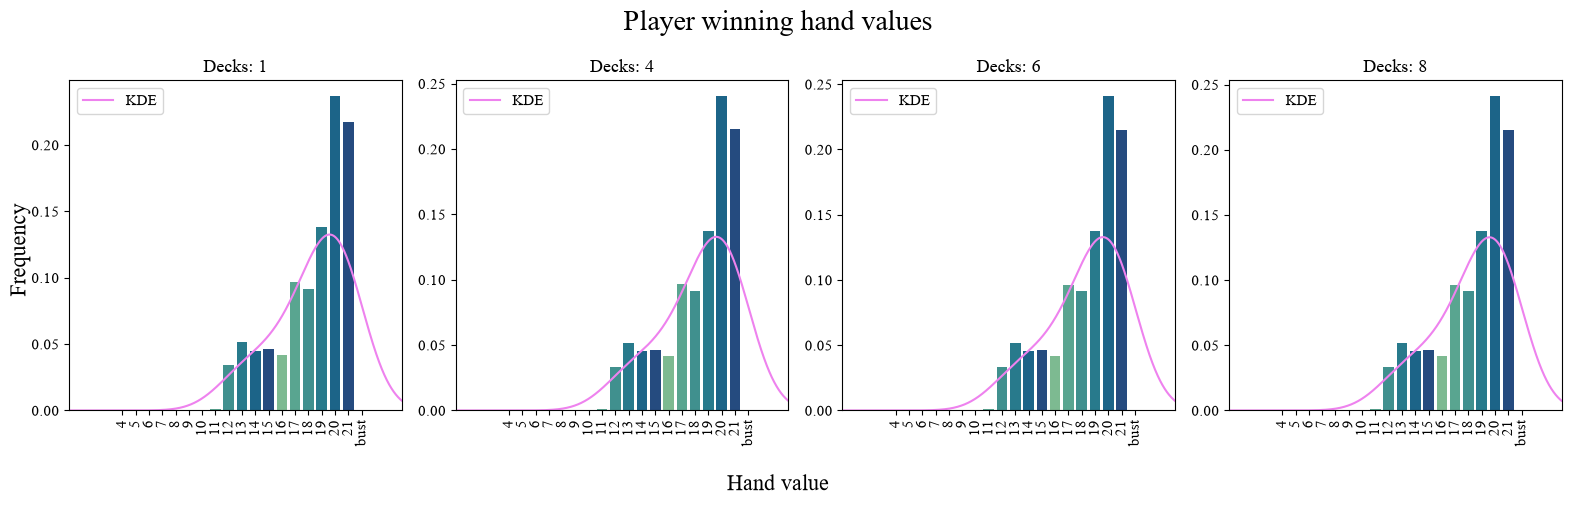

In [78]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_18_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["player_winning_value_count"]/df["player_winning_value_count"].sum(), color=sns.color_palette("crest"))

    values = df.index.to_numpy()
    weights = (df["player_winning_value_count"]/df["player_winning_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="violet", label="KDE")
    ax[i].set_xlim(0, 25)

    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Player winning hand values", fontsize=20)

fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Player_winning_hand_values_18.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

### Player losing hands

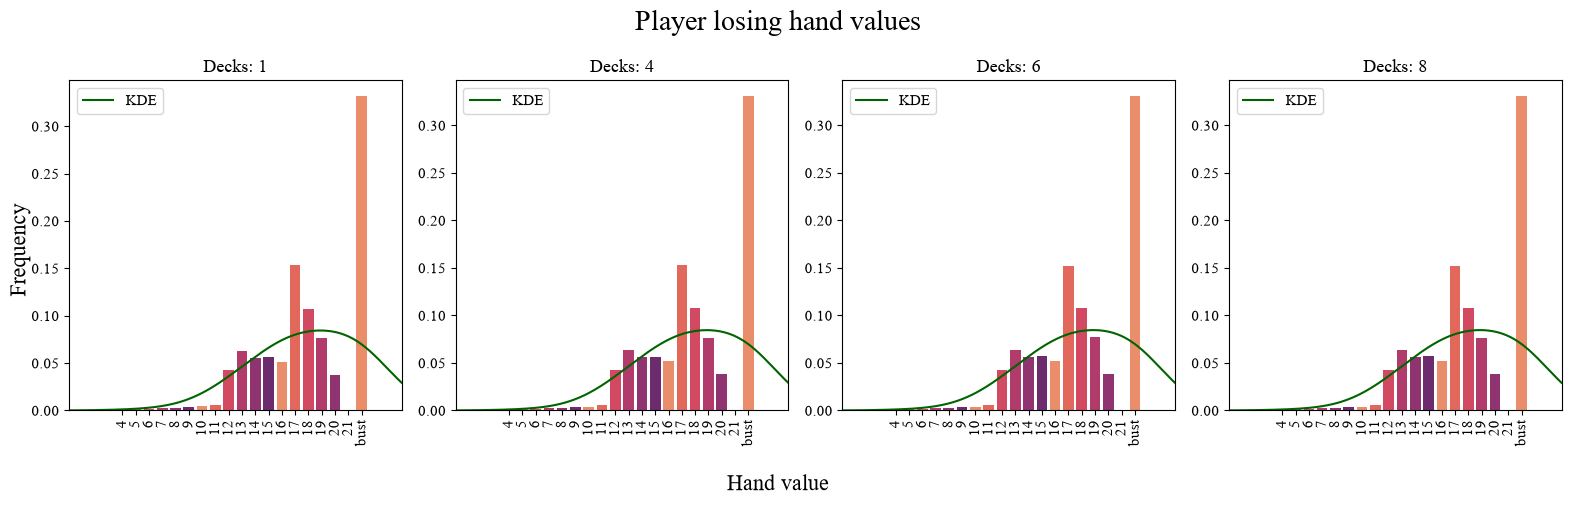

In [79]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_18_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["player_losing_value_count"]/df["player_losing_value_count"].sum(), color=sns.color_palette("flare"))

    values = df.index.to_numpy()
    weights = (df["player_losing_value_count"]/df["player_losing_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="darkgreen", label="KDE")
    ax[i].set_xlim(0, 25)

    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Player losing hand values", fontsize=20)
fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Player_losing_hand_values_18.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

### Dealer winning hands

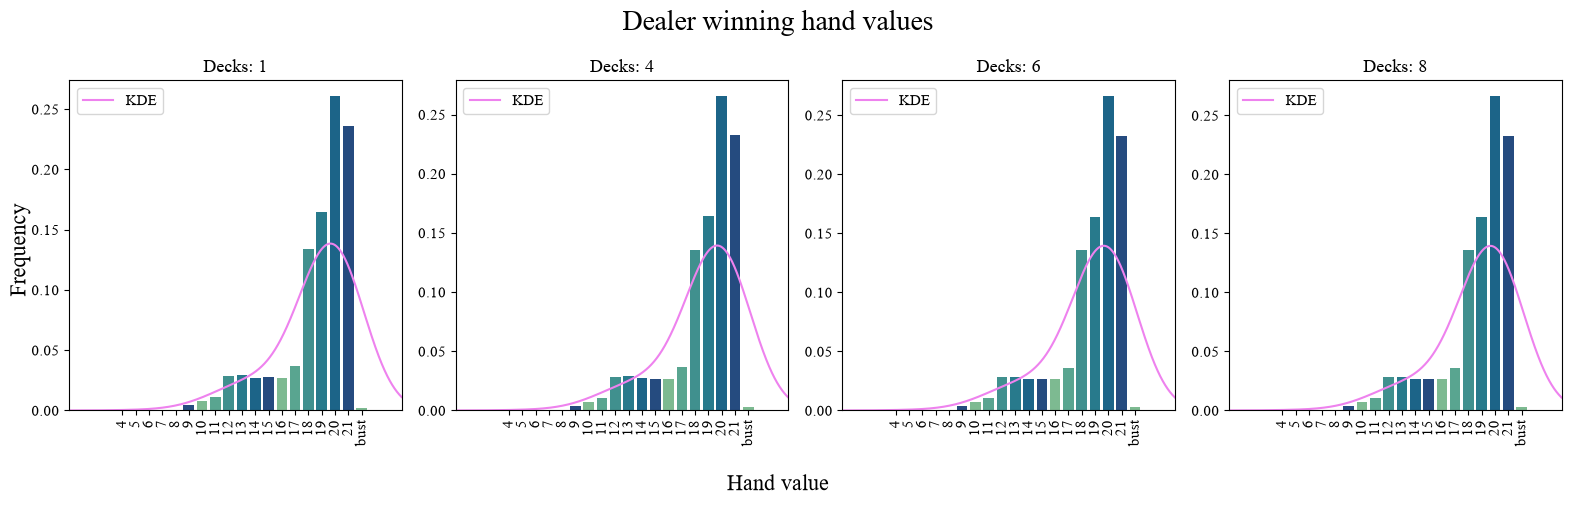

In [81]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_18_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["casino_winning_value_count"]/df["casino_winning_value_count"].sum(), color=sns.color_palette("crest"))

    values = df.index.to_numpy()
    weights = (df["casino_winning_value_count"]/df["casino_winning_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="violet", label="KDE")
    ax[i].set_xlim(0, 25)

    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Dealer winning hand values", fontsize=20)

fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Casino_winning_hand_values_18.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

### Dealer losing hands

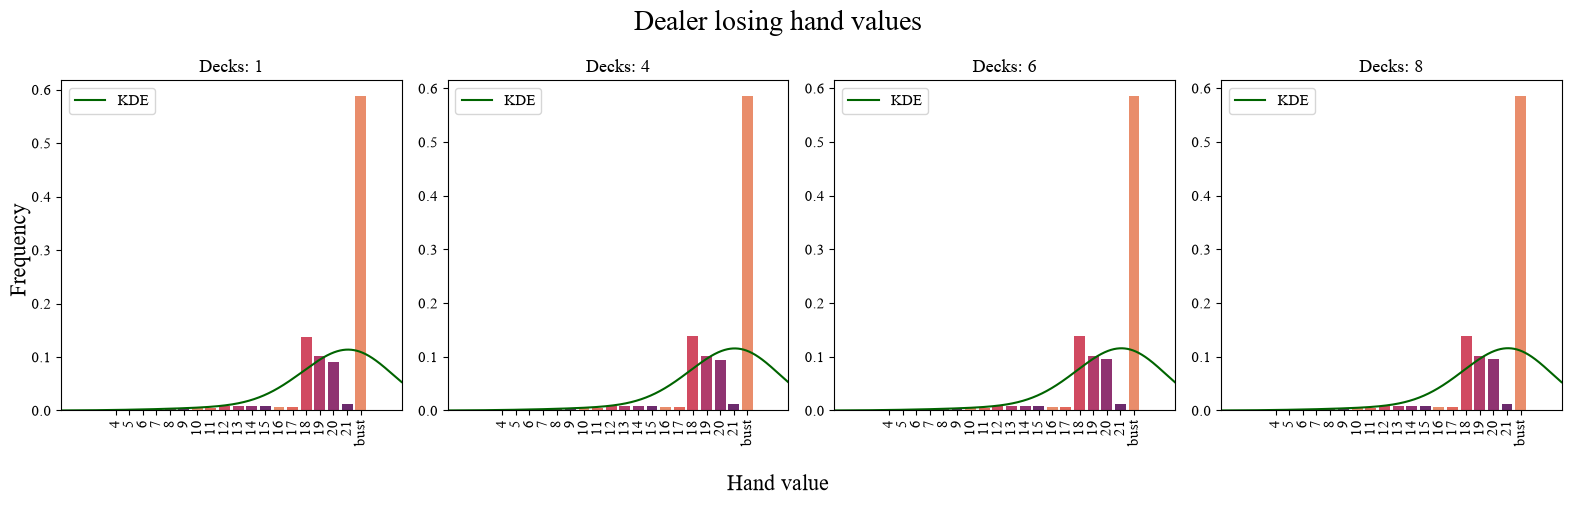

In [83]:
#@TODO: HAS a BUG, NEED TO RE-RUN ALL
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

xtick_labels = [str(i) for i in np.arange(4, 22)]
xtick_labels.extend(["bust"])

for (i,df),deck_number in zip(enumerate(hit_18_dfs), DECK_NUMBER):
    ax[i].bar(df.index, df["casino_losing_value_count"]/df["casino_losing_value_count"].sum(), color=sns.color_palette("flare"))

    values = df.index.to_numpy()
    weights = (df["casino_losing_value_count"]/df["casino_losing_value_count"].sum()).to_numpy()

    kde_ = gaussian_kde(values, weights=weights)
    kde_x = np.linspace(0,25,5000)


    ax[i].plot(kde_x,kde_(kde_x), color="darkgreen", label="KDE")
    ax[i].set_xlim(0, 25)

    ax[i].set_xticks(np.arange(4, 23))
    ax[i].set_xticklabels(xtick_labels, rotation=90)
    ax[i].set_title(f"Decks: {deck_number}")
    ax[i].legend()

fig.suptitle("Dealer losing hand values", fontsize=20)
fig.supxlabel("Hand value", fontsize=16)
fig.supylabel("Frequency", fontsize=16)
fig.tight_layout()

plt.savefig(os.path.join(PATH2FIGURES, "Casino_losing_hand_values_18.png"),
            format="png",
            dpi=300,
            bbox_inches='tight')

plt.show()

# Statistics

## Casino edge (%): mean &pm; SE

In [87]:
all_metrics_dfs = [ pd.read_csv(f, sep="\t").set_index("random_seed") for f in PATH2ALL_METRICS]
all_metrics_dfs[0].head()

,simulation_times,casino_edge (%),player_winning_times,casino_winning_times,pushes,player_total_bet,player_won_money,player_mean_winning_value,player_mean_losing_value,player_winning_less_18,...,split_times,split_winning_times,casino_mean_winning_value,casino_mean_losing_value,casino_winning_less_17,casino_winning_less_22,casino_winning_more_21,casino_loss_less_17,casino_loss_less_22,casino_bust_times
random_seed,,,,,,,,,,,,,,,,,,,,,
944904,2000000,0.5177,889784,980111,172120,2258161,-11690.5,18.77,18.27,304772,...,38830,39257,18.21,19.15,221433,757738,940,218962,327560,343262
625095,2000000,0.4533,890937,979556,171685,2258408,-10236.5,18.76,18.26,305025,...,38814,39384,18.21,19.15,220064,758528,964,218922,328801,343214
684179,2000000,0.7011,888527,981237,172359,2258385,-15834.5,18.76,18.27,304261,...,38954,39142,18.21,19.14,221464,758886,887,218667,327211,342649
897213,2000000,0.6227,889787,981904,170812,2259199,-14069.0,18.76,18.27,305104,...,39166,39462,18.21,19.15,220754,760228,922,218133,328335,343319
578292,2000000,0.4878,890703,980182,171469,2258370,-11016.0,18.76,18.26,305489,...,39062,39506,18.21,19.15,220768,758491,923,219355,327919,343429


In [94]:
def trim_metric_dfs(list_dfs):
    """Only keeping those needed columns"""
    temp_dfs = []
    for df_ in list_dfs:
        temp_dfs.append(df_[[
            "simulation_times",
            "casino_edge (%)",
            "player_winning_times",
            "casino_winning_times",
            "pushes",
            "player_bust_times",
            "player_natural_bj",
            "doubling_times",
            "doubling_winning_times",
            "doubling_losing_times",
            "doubling_pushes",
            "split_times",
            "casino_bust_times"
        ]])

    for trimmed_df in temp_dfs:
        trimmed_df["total_hands"] = np.around(trimmed_df["player_winning_times"]+trimmed_df["casino_winning_times"] + trimmed_df["pushes"], 2)
        trimmed_df["player_winning_percentage"] = np.around(trimmed_df["player_winning_times"] * 100 / trimmed_df["total_hands"],2)
        trimmed_df["casino_winning_percentage"] = np.around(trimmed_df["casino_winning_times"] * 100 / trimmed_df["total_hands"],2)
        trimmed_df["pushes_percentage"] = np.around(trimmed_df["pushes"] * 100 / trimmed_df["total_hands"],2)
        trimmed_df["doubling_percentage"] = np.around(trimmed_df["doubling_times"] * 100 / trimmed_df["simulation_times"],2)
        trimmed_df["doubling_winning_percentage"] = np.around(trimmed_df["doubling_winning_times"] * 100 / trimmed_df["total_hands"],2)
        trimmed_df["doubling_losing_percentage"] = np.around(trimmed_df["doubling_losing_times"] * 100 / trimmed_df["total_hands"],2)
        trimmed_df["doubling_pushes_percentage"] = np.around(trimmed_df["doubling_pushes"] * 100 / trimmed_df["total_hands"],2)
        trimmed_df["player_bust_percentage"] = np.around(trimmed_df["player_bust_times"] * 100 / trimmed_df["total_hands"],2)
        trimmed_df["player_natural_bj_percentage"] = np.around(trimmed_df["player_natural_bj"] * 100 / trimmed_df["simulation_times"],2)
        trimmed_df["split_percentage"] = np.around(trimmed_df["split_times"] * 100 / trimmed_df["total_hands"],2 )
        trimmed_df["casino_bust_percentage"] = np.around(trimmed_df["casino_bust_times"] * 100/trimmed_df["total_hands"],2)
        trimmed_df["doubling_winning2doubling_percentage"] = np.around(trimmed_df["doubling_winning_times"] * 100 / trimmed_df["doubling_times"],2)
        trimmed_df["doubling_losing2doubling_percentage"] = np.around(trimmed_df["doubling_losing_times"] * 100 / trimmed_df["doubling_times"],2)
        trimmed_df["doubling_pushes2doubling_percentage"] = np.around(trimmed_df["doubling_pushes"] * 100 / trimmed_df["doubling_times"],2)
        trimmed_df["player_bust2losing_percentage"] = np.around(trimmed_df["player_bust_times"] * 100 / trimmed_df["casino_winning_times"],2)
        trimmed_df["casino_bust2losing_percentage"] = np.around(trimmed_df["casino_bust_times"] * 100 / trimmed_df["player_winning_times"],2)

        trimmed_df.drop(columns=["player_winning_times",
                                "casino_winning_times",
                                "pushes",
                                "player_bust_times",
                                "player_natural_bj",
                                "doubling_times",
                                "doubling_winning_times",
                                "doubling_losing_times",
                                "doubling_pushes",
                                "split_times",
                                "casino_bust_times"], inplace=True)
    return temp_dfs

trimmed_dfs = trim_metric_dfs(all_metrics_dfs)
trimmed_dfs[0].head()

,simulation_times,casino_edge (%),total_hands,player_winning_percentage,casino_winning_percentage,pushes_percentage,doubling_percentage,doubling_winning_percentage,doubling_losing_percentage,doubling_pushes_percentage,player_bust_percentage,player_natural_bj_percentage,split_percentage,casino_bust_percentage,doubling_winning2doubling_percentage,doubling_losing2doubling_percentage,doubling_pushes2doubling_percentage,player_bust2losing_percentage,casino_bust2losing_percentage
random_seed,,,,,,,,,,,,,,,,,,,
944904,2000000,0.5177,2042015,43.57,48.00,8.43,10.04,5.27,3.82,0.75,15.79,4.80,1.90,16.81,53.57,38.83,7.59,32.89,38.58
625095,2000000,0.4533,2042178,43.63,47.97,8.41,10.04,5.27,3.82,0.75,15.72,4.78,1.90,16.81,53.56,38.84,7.60,32.78,38.52
684179,2000000,0.7011,2042123,43.51,48.05,8.44,10.04,5.23,3.85,0.74,15.75,4.78,1.91,16.78,53.22,39.20,7.58,32.77,38.56
897213,2000000,0.6227,2042503,43.56,48.07,8.36,10.05,5.26,3.84,0.74,15.80,4.81,1.92,16.81,53.49,39.01,7.50,32.87,38.58
578292,2000000,0.4878,2042354,43.61,47.99,8.40,10.01,5.25,3.81,0.74,15.74,4.79,1.91,16.82,53.58,38.86,7.56,32.80,38.56


In [98]:
trimmed_dfs[0]["casino_edge (%)"].mean(), trimmed_dfs[0]["casino_edge (%)"].sem()

(np.float64(0.523208), np.float64(0.01014539921464354))

In [99]:
pd.DataFrame({
    16: {17:19}
})

,16
17,19


In [155]:
def obtain_save_mean_metrics_df(list_of_dfs,
                                metric2calculate,
                                deck_number = DECK_NUMBER,
                                path2metrics_results =PATH2METRICS_RESULTS,
                                return_df = False):
    """Metrics per dealer must hit"""

    final_df = pd.DataFrame(index=["16","17","18"],
                            columns=list(deck_number))


    for df_, deck_number_ in zip(list_of_dfs[:4], list(deck_number)):
        mean_ = df_[metric2calculate].mean()
        final_df.loc["16", deck_number_] = round(mean_,4)

    for df_, deck_number_ in zip(list_of_dfs[4:8], deck_number):
        mean_ = df_[metric2calculate].mean()
        final_df.loc["17", deck_number_] = round(mean_,4)

    for df_, deck_number_ in zip(list_of_dfs[8:], deck_number):
        mean_ = df_[metric2calculate].mean()
        final_df.loc["18", deck_number_] = round(mean_,4)
        
    final_df.to_csv(os.path.join(path2metrics_results, 
                                 f"{metric2calculate}_mean.tsv"),
                    sep="\t")

    if return_df:
        return final_df
    else:
        return None


In [157]:
def obtain_save_sem_metrics_df(list_of_dfs,
                               metric2calculate,
                               deck_number = DECK_NUMBER,
                               path2metrics_results =PATH2METRICS_RESULTS,
                               return_df = False):
    """Metrics per dealer must hit"""

    final_df = pd.DataFrame(index=["16","17","18"],
                            columns=list(deck_number))


    for df_, deck_number_ in zip(list_of_dfs[:4], list(deck_number)):
        sem_ = df_[metric2calculate].sem()
        final_df.loc["16", deck_number_] = round(sem_,4)

    for df_, deck_number_ in zip(list_of_dfs[4:8], deck_number):
        sem_ = df_[metric2calculate].sem()
        final_df.loc["17", deck_number_] = round(sem_,4)

    for df_, deck_number_ in zip(list_of_dfs[8:], deck_number):
        sem_ = df_[metric2calculate].sem()
        final_df.loc["18", deck_number_] = round(sem_,4)
        
    final_df.to_csv(os.path.join(path2metrics_results, 
                                 f"{metric2calculate}_sem.tsv"),
                    sep="\t")
    if return_df:
        return final_df
    else:
        return None


In [158]:
for column in trimmed_dfs[0].columns:
    obtain_save_mean_metrics_df(trimmed_dfs,
                                metric2calculate = column)
    obtain_save_sem_metrics_df(trimmed_dfs,
                               metric2calculate=column)